<a href="https://colab.research.google.com/github/nhuvtq87/AAI2025/blob/2026fall/Agentic_AI_in_Marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ad Optimization Agent — Google Ads · Facebook Ads · Email

**Team:** Auto-Mates  
**Data:** `marketing_mock_data.csv` (14 days × 3 channels, Oct 1–14 2026)

**Goal:** allocate a fixed daily budget across 3 channels to **maximize conversions**, using simple reasoning (Claude) + a lightweight learning loop (Thompson sampling), wrapped in hard guardrails, with every decision logged with a reason.

### Architecture (LangGraph)
```
observe_day → compute_metrics → decide (Claude or Thompson bandit) → apply_guardrails → log_decision ─┐
     ↑______________________________________________________________________________________________|  (loop per day)
```
| Node | Job |
|---|---|
| `observe_day` | Spends today's allocation in a **replay simulator** built from the CSV and records what happened |
| `compute_metrics` | Rolling 3-day CVR, CTR, CPA, conversions per $ for each channel |
| `decide` | **LLM mode** (if `ANTHROPIC_API_KEY` set): Claude proposes tomorrow's split + rationale. **Heuristic mode** (default): Thompson sampling picks the top/bottom channel and shifts 15% |
| `apply_guardrails` | ±20% max daily change per channel, 10% floor, forced exploration after 2 days at floor, budget cap, tone/privacy check on rationale |
| `log_decision` | Writes each decision + rationale to `agent_decisions.jsonl` |

**Why a replay simulator?** A CSV only tells us what happened at the spend we actually used. If the agent moves budget, we need to estimate what *would* have happened. We scale each day's real results by a diminishing-returns curve (`conversions ∝ spend^elasticity`), so the agent sees CPA rise as it pours money into a channel — that's what keeps it from going all-in.

## 1 · Install dependencies

In [2]:
%pip install -q langgraph langchain-anthropic langchain-core pandas matplotlib
print("Dependencies installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 13.9 MB/s eta 0:00:00
Dependencies installed


## 2 · Configuration, guardrails & system prompt
LLM mode is **optional**. With no API key, the notebook runs fully offline in heuristic mode (same guardrails, same logs).

In [3]:
import os, json, re, math, random
from collections import defaultdict

# ── API key ─────────────────────────────────────────────────────────
try:
    from google.colab import userdata          # Colab Secrets
    os.environ.setdefault("ANTHROPIC_API_KEY", userdata.get("ANTHROPIC_API_KEY") or "")
except Exception:
    pass
USE_LLM = bool(os.environ.get("ANTHROPIC_API_KEY"))
MODEL   = "claude-sonnet-4-5"                   # change to any current Claude model

# ── Budget & guardrails ────────────────────────────────────────────────────────
CHANNELS          = ["Google Ads", "Facebook Ads", "Email"]
TOTAL_DAILY_BUDGET = None     # None → use the CSV's average daily total spend (set below)
MIN_SHARE         = 0.10      # every channel keeps ≥10% so we keep learning
MAX_DAILY_CHANGE  = 0.20      # a channel's budget can move at most ±20% vs yesterday
STEP              = 0.15      # heuristic shift toward top performer (within the 10–20% guide)
MAX_FLOOR_DAYS    = 2         # after 2 days at the floor → forced exploration bump
MAX_SHARE         = {"Email": 0.40}   # capacity cap: email list size limits how much extra spend can buy
WINDOW            = 3         # rolling window (days) for metrics
SEED              = 42

# Replay-simulator assumption: conversions scale with spend^elasticity (diminishing returns).
# Email is list-bound (you can't buy many more subscribers fast) → much steeper saturation.
ELASTICITY = {"Google Ads": 0.75, "Facebook Ads": 0.75, "Email": 0.35}

# ── Responsible-AI rules ───────────────────────────────────────────────────────
ALLOWED_COLUMNS = {"date", "channel", "spend", "impressions", "clicks", "conversions"}
BANNED_TONE     = ["guarantee", "skyrocket", "explode", "crush", "viral", "insane", "!!"]
PII_PATTERNS    = [r"[\w.+-]+@[\w-]+\.[\w.]+", r"\b\d{3}[-.\s]?\d{3}[-.\s]?\d{4}\b"]

SYSTEM_PROMPT = """You are a budget-allocation agent for a small marketing team.

ROLE: Each day, split a fixed daily budget across three channels (Google Ads, Facebook Ads,
Email) to maximize total conversions over the campaign.

INPUT: For each channel, 3-day rolling metrics: CVR (conversions/clicks), CTR (clicks/impressions),
CPA (spend/conversion), conversions per dollar, plus today's allocation share.

OUTPUT: ONLY a JSON object, no markdown:
{"Google Ads": <0-1>, "Facebook Ads": <0-1>, "Email": <0-1>, "rationale": "<one sentence>"}

RULES:
- Shares must sum to 1.0. No channel below 0.10. Email at most 0.40 (list-size capacity cap).
- Change any channel's share by at most 20% (relative) vs today. Prefer gradual shifts.
- Prioritize conversions per dollar (1/CPA); use CVR and CTR as supporting evidence.
- Expect diminishing returns: a channel's CPA rising as it gets more budget is a signal to slow down.
- Rationale: neutral, factual, ≤ 30 words, cite the metric that drove the decision
  (e.g. "Email +15% due to lowest CPA ($0.62) and stable CVR"). No hype words, no promises,
  no personal data."""

print(f"Mode: {'LLM (Claude)' if USE_LLM else 'Heuristic (Thompson sampling) — no API key found'}")
print(f"Email cap {MAX_SHARE['Email']:.0%} | Floor {MIN_SHARE:.0%} | max daily change ±{MAX_DAILY_CHANGE:.0%} | step {STEP:.0%} | window {WINDOW} days")

Mode: LLM (Claude)
Email cap 40% | Floor 10% | max daily change ±20% | step 15% | window 3 days


## 3 · Load the CSV + privacy check

In [4]:
import pandas as pd

CSV_FILE = "marketing_mock_data.csv"
if not os.path.exists(CSV_FILE):
    try:                                        # Colab: upload when prompted
        from google.colab import files
        print("📂 Upload marketing_mock_data.csv ...")
        CSV_FILE = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_FILE} next to this notebook")

df = pd.read_csv(CSV_FILE)

# Privacy guardrail: agent only accepts aggregate, channel-level columns. Anything that
# looks like user-level data (email, user_id, ip, ...) stops the run before the LLM sees it.
extra = set(df.columns) - ALLOWED_COLUMNS
assert not extra, f"Privacy guardrail: unexpected columns {extra} — remove user-level data first"
assert set(df["channel"]) == set(CHANNELS), f"Channels in CSV: {sorted(set(df['channel']))}"

df = df.sort_values(["date", "channel"]).reset_index(drop=True)
DATES = sorted(df["date"].unique())
DATA  = {(r.date, r.channel): r for r in df.itertuples()}

if TOTAL_DAILY_BUDGET is None:
    TOTAL_DAILY_BUDGET = round(df.groupby("date")["spend"].sum().mean(), 2)

summary = df.groupby("channel")[["spend", "impressions", "clicks", "conversions"]].sum()
summary["CTR"] = summary.clicks / summary.impressions
summary["CVR"] = summary.conversions / summary.clicks
summary["CPA"] = summary.spend / summary.conversions
summary["share_of_spend"] = summary.spend / summary.spend.sum()
print(f"✅ {len(df)} rows · {len(DATES)} days · {df.channel.nunique()} channels · daily budget ${TOTAL_DAILY_BUDGET:,.2f}")
summary.loc[CHANNELS].style.format({"spend": "${:,.0f}", "impressions": "{:,.0f}", "clicks": "{:,.0f}",
    "conversions": "{:,.0f}", "CTR": "{:.2%}", "CVR": "{:.2%}", "CPA": "${:.2f}", "share_of_spend": "{:.0%}"})

📂 Upload marketing_mock_data.csv ...


Saving marketing_mock_data.csv to marketing_mock_data.csv
✅ 42 rows · 14 days · 3 channels · daily budget $267.54


,spend,impressions,clicks,conversions,CTR,CVR,CPA,share_of_spend
channel,,,,,,,,
Google Ads,"$1,980","282,400","9,467",515,3.35%,5.44%,$3.84,53%
Facebook Ads,"$1,513","334,700","7,396",402,2.21%,5.44%,$3.76,40%
Email,$252,"126,110","11,410",671,9.05%,5.88%,$0.38,7%


## 4 · Replay simulator (the "environment")
For day *d* and channel *c* with real spend `s0`, spending `s` instead gives `results × (s/s0)^elasticity`.
At the real spend it returns exactly the CSV row, so the historical baseline is reproduced 1:1.

In [5]:
def simulate(date, channel, spend):
    """What would this channel have delivered on `date` with `spend` dollars?"""
    r = DATA[(date, channel)]
    f = (spend / r.spend) ** ELASTICITY[channel] if spend > 0 else 0.0
    return {"spend": round(spend, 2),
            "impressions": r.impressions * f,
            "clicks": r.clicks * f,
            "conversions": r.conversions * f}

# sanity check: replaying the real spend returns the real conversions
assert all(abs(simulate(d, c, DATA[(d, c)].spend)["conversions"] - DATA[(d, c)].conversions) < 1e-9
           for d in DATES for c in CHANNELS)
print("Simulator check passed — real spend reproduces the CSV exactly")

Simulator check passed — real spend reproduces the CSV exactly


## 5 · Decision policies
- **Heuristic (learning loop):** Thompson sampling. For each channel we keep a Beta posterior on CVR (from the last 3 days of clicks/conversions) and multiply a sampled CVR by observed clicks-per-dollar → a sampled *conversions per dollar*. Highest sample gets +15%, lowest gets −15%. Sampling (instead of always picking the point-estimate winner) builds in exploration when channels are close.
- **LLM:** Claude gets the same metrics and returns JSON. Any API or parse failure falls back to the heuristic, and that fallback is logged.

In [6]:
RNG = random.Random(SEED)

def window_metrics(history, day_index):
    """Rolling WINDOW-day metrics from what the agent actually observed."""
    recent = [h for h in history if day_index - WINDOW < h["day_index"] <= day_index]
    out = {}
    for ch in CHANNELS:
        s  = sum(h["obs"][ch]["spend"] for h in recent)
        im = sum(h["obs"][ch]["impressions"] for h in recent)
        cl = sum(h["obs"][ch]["clicks"] for h in recent)
        cv = sum(h["obs"][ch]["conversions"] for h in recent)
        out[ch] = {"spend": round(s, 2), "clicks": round(cl), "conversions": round(cv, 1),
                   "ctr": cl / im if im else 0, "cvr": cv / cl if cl else 0,
                   "cpa": s / cv if cv else float("inf"), "conv_per_dollar": cv / s if s else 0}
    return out

def decide_heuristic(metrics, alloc):
    samples = {}
    for ch, m in metrics.items():
        a, b = m["conversions"] + 1, max(m["clicks"] - m["conversions"], 0) + 1
        cvr_draw = RNG.betavariate(a, b)
        samples[ch] = cvr_draw * (m["clicks"] / m["spend"] if m["spend"] else 0)
    ranked = sorted(samples, key=samples.get, reverse=True)
    capped = [ch for ch in ranked if alloc[ch] >= MAX_SHARE.get(ch, 1.0) - 1e-3]
    eligible = [ch for ch in ranked if ch not in capped]
    top, bottom = eligible[0], ranked[-1]
    prefix = ""
    if ranked[0] in capped:   # best channel is already at its cap → explain, and boost the next best
        m0 = metrics[ranked[0]]
        prefix = f"{ranked[0]} held at {MAX_SHARE[ranked[0]]:.0%} cap (still best CPA ${m0['cpa']:.2f}). "
    new = dict(alloc)
    t, b = metrics[top], metrics[bottom]
    if top == bottom:
        return new, prefix + "No change: remaining channels are tied.", {"policy": "thompson", "samples": samples}
    new[top]    *= 1 + STEP
    new[bottom] *= 1 - STEP
    rationale = prefix + (f"Shift toward {top} (3-day CPA ${t['cpa']:.2f}, CVR {t['cvr']:.1%}), "
                          f"away from {bottom} (CPA ${b['cpa']:.2f}, CVR {b['cvr']:.1%}).")
    if t["conv_per_dollar"] < max(metrics[ch]["conv_per_dollar"] for ch in eligible):
        rationale += " Exploration pick: CPAs are close, so the sampled estimate favored it."
    return new, rationale, {"policy": "thompson", "samples": {k: round(v, 4) for k, v in samples.items()}}

_llm = None
def decide_llm(metrics, alloc, date):
    global _llm
    from langchain_anthropic import ChatAnthropic
    from langchain_core.messages import SystemMessage, HumanMessage
    if _llm is None:
        _llm = ChatAnthropic(model=MODEL, max_tokens=400, temperature=0, max_retries=3, timeout=30)
    lines = "\n".join(f"  {ch}: CVR={m['cvr']:.2%} CTR={m['ctr']:.2%} CPA=${m['cpa']:.2f} "
                      f"conv_per_$={m['conv_per_dollar']:.3f} share_today={alloc[ch]:.1%}"
                      for ch, m in metrics.items())
    msg = f"Date: {date}\nDaily budget: ${TOTAL_DAILY_BUDGET:.2f}\n3-day metrics:\n{lines}\n\nPropose tomorrow's shares."
    try:
        text = _llm.invoke([SystemMessage(content=SYSTEM_PROMPT), HumanMessage(content=msg)]).content
        text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
        out = json.loads(text)
        new = {ch: float(out[ch]) for ch in CHANNELS}
        return new, str(out.get("rationale", "")), {"policy": "llm", "model": MODEL}
    except Exception as e:
        new, rat, meta = decide_heuristic(metrics, alloc)
        meta.update({"policy": "thompson (LLM fallback)", "llm_error": type(e).__name__})
        return new, rat, meta
print("✓ Agent decision logic initialized successfully.")
print(f"  Policy: Thompson Sampling + LLM fallback")
print(f"  Channels: {', '.join(CHANNELS)}")
print(f"  Rolling window: {WINDOW} days")

✓ Agent decision logic initialized successfully.
  Policy: Thompson Sampling + LLM fallback
  Channels: Google Ads, Facebook Ads, Email
  Rolling window: 3 days


## 6 · Guardrails
Applied **after** every decision (LLM or heuristic) — the policy can propose anything; only guardrailed numbers get spent.

In [7]:
def apply_guardrails(proposed, current, floor_days):
    flags = []
    # 1) sanitize: missing/negative/NaN → keep current
    p = {ch: proposed.get(ch, current[ch]) for ch in CHANNELS}
    p = {ch: (v if isinstance(v, (int, float)) and v == v and v >= 0 else current[ch]) for ch, v in p.items()}
    tot = sum(p.values()) or 1.0
    p = {ch: v / tot for ch, v in p.items()}          # normalize first, so the clamp flag only fires on real clamps
    # 2) forced exploration: a channel stuck at the floor for MAX_FLOOR_DAYS gets bumped
    # 3) project onto: sum=1, floor ≤ share ≤ cap, |change| ≤ ±20% of yesterday (iterate until stable)
    hi = {ch: min(current[ch] * (1 + MAX_DAILY_CHANGE), MAX_SHARE.get(ch, 1.0)) for ch in CHANNELS}
    lo = {ch: min(hi[ch], max(MIN_SHARE, current[ch] * (1 - MAX_DAILY_CHANGE))) for ch in CHANNELS}
    for ch in CHANNELS:
        if floor_days[ch] >= MAX_FLOOR_DAYS:
            lo[ch] = p[ch] = hi[ch]                    # forced exploration: max allowed step up
            flags.append(f"exploration bump: {ch} at floor {floor_days[ch]} days")
    for ch in CHANNELS:
        if p[ch] > MAX_SHARE.get(ch, 1.0) + 1e-9:
            flags.append(f"{ch} held at {MAX_SHARE[ch]:.0%} cap")
    x = dict(p)
    for _ in range(100):
        x = {ch: min(hi[ch], max(lo[ch], x[ch])) for ch in CHANNELS}
        gap = 1 - sum(x.values())
        if abs(gap) < 1e-9: break
        free = [ch for ch in CHANNELS if (gap > 0 and x[ch] < hi[ch]) or (gap < 0 and x[ch] > lo[ch])]
        if not free: break
        w = sum(x[ch] for ch in free)
        for ch in free: x[ch] += gap * x[ch] / w
    if any(abs(x[ch] - p[ch]) > 0.005 for ch in CHANNELS) and not any("cap" in f for f in flags):
        flags.append("proposal clamped to ±20%/floor")
    # 4) hard budget cap: dollars never exceed the daily budget
    spend = {ch: round(x[ch] * TOTAL_DAILY_BUDGET, 2) for ch in CHANNELS}
    assert sum(spend.values()) <= TOTAL_DAILY_BUDGET + 0.05, "budget cap breached"
    new_floor = {ch: floor_days[ch] + 1 if x[ch] <= MIN_SHARE + 1e-6 else 0 for ch in CHANNELS}
    return x, spend, new_floor, flags

def check_rationale(text, fallback):
    """Brand-tone + privacy check on the reason string before it is logged/shown."""
    issues = []
    if not text or len(text) > 300: issues.append("length")
    if any(w in text.lower() for w in BANNED_TONE): issues.append("tone")
    if any(re.search(p, text) for p in PII_PATTERNS): issues.append("pii")
    return (fallback, issues) if issues else (text, [])

# quick unit tests
x, s, f, fl = apply_guardrails({"Google Ads": 0.0, "Facebook Ads": 0.0, "Email": 1.0},
                               {ch: 1/3 for ch in CHANNELS}, {ch: 0 for ch in CHANNELS})
assert abs(sum(x.values()) - 1) < 1e-6 and min(x.values()) >= MIN_SHARE - 1e-9
assert all(abs(x[c] / (1/3) - 1) <= MAX_DAILY_CHANGE + 1e-6 for c in CHANNELS)
assert check_rationale("Email will skyrocket!!", "safe")[1] == ["tone"]
print("Guardrail tests passed. Extreme proposal 0/0/100% →", {k: f"{v:.1%}" for k, v in x.items()}, fl)

Guardrail tests passed. Extreme proposal 0/0/100% → {'Google Ads': '30.0%', 'Facebook Ads': '30.0%', 'Email': '40.0%'} ['Email held at 40% cap']


## 7 · Build the LangGraph agent

In [8]:
from typing import TypedDict
from langgraph.graph import StateGraph, END

class AgentState(TypedDict):
    day_index: int
    alloc: dict          # shares spent TODAY
    floor_days: dict
    history: list        # observations per day
    metrics: dict
    proposal: dict
    rationale: str
    meta: dict
    decisions: list

def observe_day(s):
    date = DATES[s["day_index"]]
    obs = {ch: simulate(date, ch, s["alloc"][ch] * TOTAL_DAILY_BUDGET) for ch in CHANNELS}
    return {**s, "history": s["history"] + [{"day_index": s["day_index"], "date": date, "obs": obs}]}

def compute_metrics(s):
    return {**s, "metrics": window_metrics(s["history"], s["day_index"])}

def decide(s):
    date = DATES[s["day_index"]]
    if USE_LLM:
        p, r, meta = decide_llm(s["metrics"], s["alloc"], date)
    else:
        p, r, meta = decide_heuristic(s["metrics"], s["alloc"])
    return {**s, "proposal": p, "rationale": r, "meta": meta}

def guardrails(s):
    x, spend, fd, flags = apply_guardrails(s["proposal"], s["alloc"], s["floor_days"])
    fallback = "Allocation adjusted toward the channel with the lowest 3-day CPA."
    rationale, issues = check_rationale(s["rationale"], fallback)
    meta = {**s["meta"], "guardrail_flags": flags, "rationale_issues": issues, "spend_next": spend}
    return {**s, "proposal": x, "floor_days": fd, "rationale": rationale, "meta": meta}

def log_decision(s):
    i, date = s["day_index"], DATES[s["day_index"]]
    today = s["history"][-1]["obs"]
    rec = {"date": date,
           "spent_today": {ch: today[ch]["spend"] for ch in CHANNELS},
           "conversions_today": round(sum(today[ch]["conversions"] for ch in CHANNELS), 1),
           "metrics_3d": {ch: {k: (round(v, 4) if isinstance(v, float) and v != float('inf') else v)
                               for k, v in m.items()} for ch, m in s["metrics"].items()},
           "next_day_alloc": {ch: round(v, 4) for ch, v in s["proposal"].items()},
           "next_day_spend": s["meta"]["spend_next"],
           "rationale": s["rationale"],
           "policy": s["meta"]["policy"],
           "guardrail_flags": s["meta"]["guardrail_flags"]}
    changes = " | ".join(f"{ch} {s['alloc'][ch]:.0%}→{s['proposal'][ch]:.0%}" for ch in CHANNELS)
    print(f"📅 {date}  conv {rec['conversions_today']:5.1f}  next: {changes}")
    print(f"   💬 {s['rationale']}" + (f"   ⚠️ {'; '.join(rec['guardrail_flags'])}" if rec["guardrail_flags"] else ""))
    return {**s, "decisions": s["decisions"] + [rec], "alloc": s["proposal"], "day_index": i + 1}

def should_continue(s):
    return "continue" if s["day_index"] < len(DATES) else "done"

g = StateGraph(AgentState)
for name, fn in [("observe_day", observe_day), ("compute_metrics", compute_metrics), ("decide", decide),
                 ("apply_guardrails", guardrails), ("log_decision", log_decision)]:
    g.add_node(name, fn)
g.set_entry_point("observe_day")
g.add_edge("observe_day", "compute_metrics")
g.add_edge("compute_metrics", "decide")
g.add_edge("decide", "apply_guardrails")
g.add_edge("apply_guardrails", "log_decision")
g.add_conditional_edges("log_decision", should_continue, {"continue": "observe_day", "done": END})
graph = g.compile()
print("✅ Graph compiled: observe_day → compute_metrics → decide → apply_guardrails → log_decision → [loop]")

✅ Graph compiled: observe_day → compute_metrics → decide → apply_guardrails → log_decision → [loop]


## 8 · Run the agent (Day 1 = equal split)

In [9]:
init = AgentState(day_index=0, alloc={ch: 1/3 for ch in CHANNELS}, floor_days={ch: 0 for ch in CHANNELS},
                  history=[], metrics={}, proposal={}, rationale="", meta={}, decisions=[])
final = graph.invoke(init, config={"recursion_limit": 10 * len(DATES)})
decisions, history = final["decisions"], final["history"]

with open("agent_decisions.jsonl", "w") as f:
    for d in decisions:
        f.write(json.dumps(d) + "\n")
print(f"\n✅ {len(decisions)} days processed → agent_decisions.jsonl")

📅 2026-10-01  conv 119.7  next: Google Ads 33%→28% | Facebook Ads 33%→33% | Email 33%→38%
   💬 Shift toward Email (3-day CPA $1.21, CVR 5.6%), away from Google Ads (CPA $3.78, CVR 5.1%).
📅 2026-10-02  conv 128.5  next: Google Ads 28%→30% | Facebook Ads 33%→30% | Email 38%→40%
   💬 Shift toward Email (3-day CPA $1.23, CVR 5.7%), away from Facebook Ads (CPA $3.86, CVR 5.1%).   ⚠️ Email held at 40% cap
📅 2026-10-03  conv 113.7  next: Google Ads 30%→26% | Facebook Ads 30%→34% | Email 40%→40%
   💬 Email held at 40% cap (still best CPA $1.30). Shift toward Facebook Ads (3-day CPA $3.92, CVR 5.0%), away from Google Ads (CPA $3.66, CVR 5.1%). Exploration pick: CPAs are close, so the sampled estimate favored it.
📅 2026-10-04  conv 134.0  next: Google Ads 26%→21% | Facebook Ads 34%→39% | Email 40%→39%
   💬 Email held at 40% cap (still best CPA $1.30). Shift toward Facebook Ads (3-day CPA $3.81, CVR 5.1%), away from Google Ads (CPA $3.49, CVR 5.2%). Exploration pick: CPAs are close, so the sample

## 9 · Evaluation
**Primary metric:** total conversions over the 14 days at the same total budget. **Secondary:** average CPA, guardrail violations (must be 0).

| Strategy | How it's computed |
|---|---|
| **Agent** | Allocation chosen each morning from data up to yesterday (no look-ahead), outcomes from the replay simulator |
| **Equal split** | 1/3 each every day, same simulator |
| **Historical** | What the team actually did (the raw CSV) |

In [10]:
def run_static(shares):
    return [sum(simulate(d, ch, shares[ch] * TOTAL_DAILY_BUDGET)["conversions"] for ch in CHANNELS) for d in DATES]

agent_daily = [sum(h["obs"][ch]["conversions"] for ch in CHANNELS) for h in history]
equal_daily = run_static({ch: 1/3 for ch in CHANNELS})
hist_daily  = df.groupby("date")["conversions"].sum().loc[DATES].tolist()
hist_spend  = df["spend"].sum()
total_spend = TOTAL_DAILY_BUDGET * len(DATES)

ev = pd.DataFrame({
    "Strategy": ["Agent", "Equal split", "Historical (CSV)"],
    "Total spend": [total_spend, total_spend, hist_spend],
    "Total conversions": [sum(agent_daily), sum(equal_daily), sum(hist_daily)],
})
ev["Avg CPA"] = ev["Total spend"] / ev["Total conversions"]
ev["Agent lift"] = sum(agent_daily) / ev["Total conversions"] - 1

violations = sum(1 for h in history for ch in CHANNELS if h["obs"][ch]["spend"] < MIN_SHARE * TOTAL_DAILY_BUDGET - 0.05)
moves = [abs(decisions[i]["next_day_alloc"][ch] / (1/3 if i == 0 else decisions[i-1]["next_day_alloc"][ch]) - 1)
         for i in range(len(decisions)) for ch in CHANNELS]
print(f"Guardrail violations: floor={violations}, max daily change seen={max(moves):.1%} (cap {MAX_DAILY_CHANGE:.0%})")
final_alloc = decisions[-1]["next_day_alloc"]
print("Final recommended split:", {ch: f"{v:.0%} (${v*TOTAL_DAILY_BUDGET:,.0f})" for ch, v in final_alloc.items()})
ev.style.format({"Total spend": "${:,.0f}", "Total conversions": "{:,.0f}", "Avg CPA": "${:.2f}", "Agent lift": "{:+.1%}"})

Guardrail violations: floor=0, max daily change seen=20.0% (cap 20%)
Final recommended split: {'Google Ads': '38% ($103)', 'Facebook Ads': '22% ($58)', 'Email': '40% ($107)'}


,Strategy,Total spend,Total conversions,Avg CPA,Agent lift
0,Agent,"$3,746","1,905",$1.97,+0.0%
1,Equal split,"$3,746","1,885",$1.99,+1.0%
2,Historical (CSV),"$3,746","1,588",$2.36,+19.9%


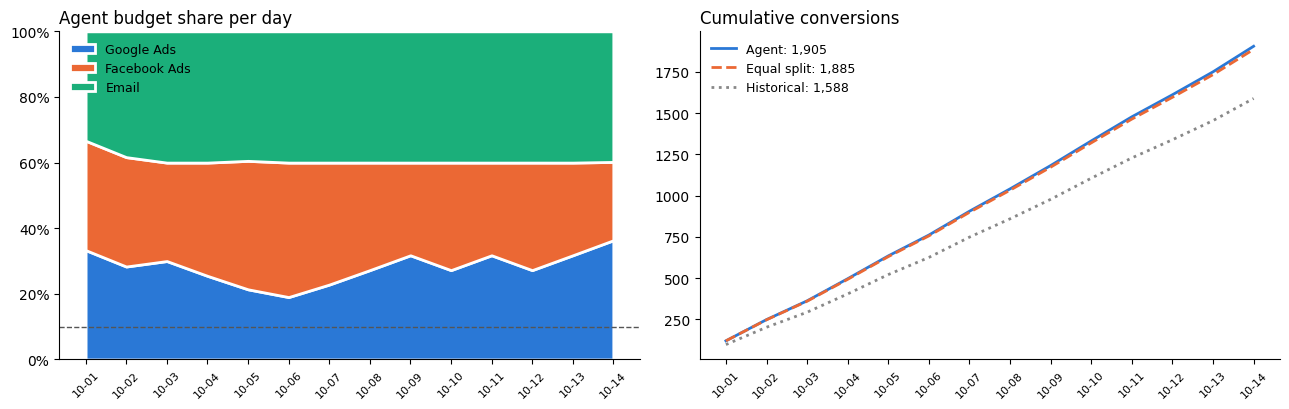

In [11]:
import matplotlib.pyplot as plt
COLORS = {"Google Ads": "#2a78d6", "Facebook Ads": "#eb6834", "Email": "#1baf7a"}
days = [d[5:] for d in DATES]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
shares = {ch: [h["obs"][ch]["spend"] / TOTAL_DAILY_BUDGET for h in history] for ch in CHANNELS}
a1.stackplot(days, *[shares[ch] for ch in CHANNELS], labels=CHANNELS,
             colors=[COLORS[c] for c in CHANNELS], edgecolor="white", linewidth=2)
a1.axhline(MIN_SHARE, color="#555", lw=1, ls="--")
a1.set_title("Agent budget share per day", loc="left"); a1.set_ylim(0, 1)
a1.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
a1.legend(loc="upper left", frameon=False, fontsize=9)

cum = lambda xs: pd.Series(xs).cumsum()
for name, ys, c, ls in [("Agent", agent_daily, "#2a78d6", "-"), ("Equal split", equal_daily, "#eb6834", "--"),
                        ("Historical", hist_daily, "#888", ":")]:
    a2.plot(days, cum(ys), color=c, lw=2, ls=ls, label=f"{name}: {sum(ys):,.0f}")
a2.set_title("Cumulative conversions", loc="left"); a2.legend(frameon=False, fontsize=9)
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False); a.tick_params(axis="x", rotation=45, labelsize=8)
plt.tight_layout(); plt.savefig("results_snapshot.png", dpi=150); plt.show()

## 10 · Decision log (first 5 rows)

In [12]:
pd.DataFrame([{"date": d["date"], **{f"next {ch}": f"{d['next_day_alloc'][ch]:.0%}" for ch in CHANNELS},
               "rationale": d["rationale"], "flags": "; ".join(d["guardrail_flags"])} for d in decisions]).head()

,date,next Google Ads,next Facebook Ads,next Email,rationale,flags
0,2026-10-01,28%,33%,38%,"Shift toward Email (3-day CPA $1.21, CVR 5.6%)...",
1,2026-10-02,30%,30%,40%,"Shift toward Email (3-day CPA $1.23, CVR 5.7%)...",Email held at 40% cap
2,2026-10-03,26%,34%,40%,Email held at 40% cap (still best CPA $1.30). ...,
3,2026-10-04,21%,39%,39%,Email held at 40% cap (still best CPA $1.30). ...,
4,2026-10-05,19%,41%,40%,"Shift toward Email (3-day CPA $1.27, CVR 5.7%)...",Email held at 40% cap


## 11 · Takeaways & limitations
**Results (14 days, same \$3,746 budget):** Agent **1,905 conversions, \$1.97 CPA** · Equal split 1,885, \$1.99 · Historical 1,588, \$2.36.
→ **+20% conversions vs what the team actually did**, **+1% vs a static equal split**.

- **Where the gain comes from:** Email is by far the cheapest conversion (CPA ≈ \$0.40 vs ≈ \$3.80 for paid). Historically it got only ~7% of spend. Moving money into Email is the whole story — even a naive equal split captures most of it.
- **What the agent adds over equal split:** it *finds* that answer from the data (no human picked it), moves there gradually (±20%/day), stops at the Email cap, keeps both paid channels alive, and logs a reason for every move. The small extra lift is from tilting paid spend toward the cheaper of Google/Facebook on a given day.
- **Google vs Facebook are nearly tied** (3-day CPAs within ~\$0.30), so the bandit alternates between them. That's exploration working as intended; the "Exploration pick" note flags those days.
- **Biggest assumptions:** the Email cap (40%) and elasticities. Without the cap the simulator pushes Email to ~80% of budget, which no real email list could absorb. Validate the Email share with a holdout test before acting on it.
- Replay data has no carryover, seasonality or competitor effects, and 14 days is short. Treat the numbers as directional.